# How do I read a GeoTIFF using Python

This How To Guide demonstrates how to read and plot data stored as a GeoTIFF using the Python `xarray` and `rasterio` packages.

We use a file from the MEaSUREs Greenland Ice Sheet Velocity InSAR data (NSIDC-0478) dataset as an example.  You can find this file on Earthdata Search using this [link](https://search.earthdata.nasa.gov/search/granules?p=C3291179132-NSIDC_CPRD&pg[0][v]=f&pg[0][id]=greenland_vel_mosaic500_2016_2017*&pg[0][gsk]=-start_date&g=G3291184653-NSIDC_CPRD&lat=71.5&long=-43.50586701434159&zoom=4.144198526269722)

## Problem

I have some data that is stored in a GeoTIFF file.  How can I read this file and plot the data it contains.

## Solution

We can read a GeoTIFF using the `xarray` and `rioxarray` packages, or using the `rasterio` package.

### Read and plot data with `xarray`

#### Read data

To read a GeoTIFF using `xarray` we set `engine="rasterio"`.  We need to import `rioxarray` to make the `rasterio` engine available to `xarray`.

In [1]:
import xarray as xr
import rioxarray

ds = xr.open_dataset("../example_data/greenland_vel_mosaic500_2016_2017_vv_v02.1.tif", engine="rasterio")
ds

<xarray.Dataset> Size: 67MB
Dimensions:      (band: 1, x: 3034, y: 5480)
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 24kB -6.59e+05 -6.585e+05 ... 8.57e+05 8.575e+05
  * y            (y) float64 44kB -6.395e+05 -6.4e+05 ... -3.378e+06 -3.379e+06
    spatial_ref  int64 8B ...
Data variables:
    band_data    (band, y, x) float32 67MB ...

Information about the coordinate reference system for the data is stored in the attributes of the `spatial_ref` _grid-mapping variable_.

In [51]:
ds.band_data.data

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]],
      shape=(1, 5480, 3034), dtype=float32)

In [24]:
ds.spatial_ref.attrs

{'crs_wkt': 'PROJCS["unnamed",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Polar_Stereographic"],PARAMETER["latitude_of_origin",70],PARAMETER["central_meridian",-45],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["Easting",SOUTH],AXIS["Northing",SOUTH]]',
 'semi_major_axis': 6378137.0,
 'semi_minor_axis': 6356752.314245179,
 'inverse_flattening': 298.257223563,
 'reference_ellipsoid_name': 'WGS 84',
 'longitude_of_prime_meridian': 0.0,
 'prime_meridian_name': 'Greenwich',
 'geographic_crs_name': 'WGS 84',
 'horizontal_datum_name': 'World Geodetic System 1984',
 'projected_crs_name': 'unnamed',
 'grid_mapping_name': 'polar_stereographic',
 'standard_parallel': 70.0,
 'straight_vertical_longitude_from_pole': -45.0,
 'false_easting': 0.0,
 'false_northing': 0.0

#### Plot Data

To plot the data as a map, we need to use the information in `spatial_ref` to define a map projection.  We use the `cartopy.crs` module for this.

The ice velocity ranges from less than 1 m/year to more than 3000 m/year.  So we use a log scale.  This is done using `matplotlib.colors.LogNorm`, which scales (or normalizes) the data on a log scale.  We use a perceptually uniform sequentional colormap[^1] from the [`cmocean`](https://matplotlib.org/cmocean/) package designed to display velocity data. 

_I am trying to figure out a good way to define the cartopy.crs.Projection object directly from the `spatial_ref` variable.  But for now, I set the keywords for the cartopy Stereographic object._

[^1] a colormap in which equal steps in data are perceived as equal steps in the color space.

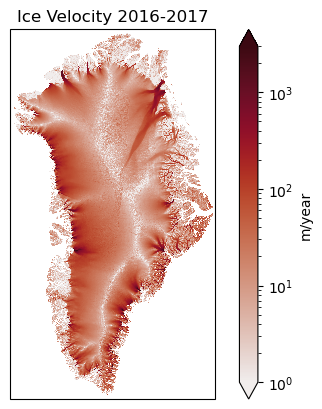

In [56]:
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cmocean

projection = ccrs.NorthPolarStereo(central_longitude=-45., true_scale_latitude=70.)

p = ds.band_data.squeeze().plot(
    subplot_kws=dict(projection=projection,),
    norm=mcolors.LogNorm(vmin=1, vmax=3000, clip=True),
    cmap=cmocean.cm.amp,
    cbar_kwargs=dict(label="m/year"),
)
p.axes.set_title("Ice Velocity 2016-2017");

### Read and plot data using `rasterio`

#### Read data

`rasterio.open` returns a `DatasetReader` object for the GeoTIFF.

In [2]:
import rasterio

src = rasterio.open("../example_data/greenland_vel_mosaic500_2016_2017_vv_v02.1.tif")

We can get Coordinate Reference System (CRS) definition

In [27]:
src.crs

CRS.from_wkt('PROJCS["unnamed",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Polar_Stereographic"],PARAMETER["latitude_of_origin",70],PARAMETER["central_meridian",-45],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1],AXIS["Easting",SOUTH],AXIS["Northing",SOUTH]]')

We can get a transform containing definition of grid.

Returns _cell-width_, _x-axis rotation_, _x-axis origin_, _y-axis rotation_, _cell_height_, _y-axis origin_

In [28]:
src.transform

Affine(500.0, 0.0, -659250.0,
       0.0, -500.0, -639250.0)

The `read` method returns a `numpy` array containing the data.

In [29]:
data = src.read(1)

#### Plot the data

We use the `show` method from `rasterio` to plot the data.  Supplying `transform=src.transform` sets the extent and aspect of the plot correctly.  The same log normalization and colormap as used in the `xarray` example are used to scale and color the plot.

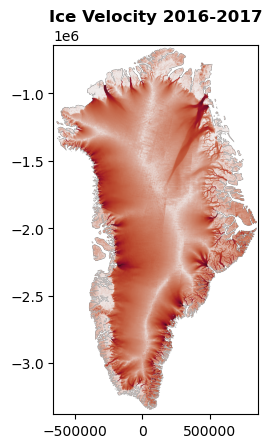

In [48]:
from rasterio.plot import show

import matplotlib.colors as mcolors  # For LogNorm
import cmocean  # For cmocean amp colormap

p = show(
    src.read(masked=True), 
    transform=src.transform, 
    cmap=cmocean.cm.amp, 
    norm=mcolors.LogNorm(vmin=1, vmax=3000, clip=True),
    title="Ice Velocity 2016-2017",
);

## Discussion

Either `rasterio` or `xarray` can be used to read a GeoTIFF.  Which of these packages you use depends on what tools you are familiar with and also what analysis you are performing.

The `xarray` package was developed for multi-dimensional arrays (e.g. arrays with more than two dimensions).  If your analysis involves time series of images, `xarray` provides methods to process datacubes with three or more dimensions.  See (Load a time series of GeoTIFFs using `xarray`)[] to create a 3D (e.g. _time_, _x_, _y_) datacube.

You can use `rasterio` to create a datacube but the advantage of `xarray` is that the dimensions and coordinates of the data are part of the datacube you create.  `rasterio` just creates a `numpy` array.

If your objective is to read a GeoTIFF and create a plot, as demonstrated in this How To Guide, then either package achieves this.